# ED anomaly detection
Flags hours where ED arrivals are unusually high.

- Method: z-score against the usual arrivals for the same hour and day of week
- Labels used only to evaluate: `is_anomaly` in `data/datasets/hourly_metrics.csv`

In [22]:
import os
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

## 1. Load ED data

In [23]:
df = pd.read_csv('../data/datasets/hourly_metrics.csv', parse_dates=['timestamp'])
ed_df = df[df['department_id'] == 1].sort_values('timestamp').reset_index(drop=True)
print(ed_df.shape)
ed_df['is_anomaly'].value_counts()

(24336, 20)


is_anomaly
0    24248
1       88
Name: count, dtype: int64

## 2. Look at an anomaly
Arrivals in the 48 hours around the first anomaly.

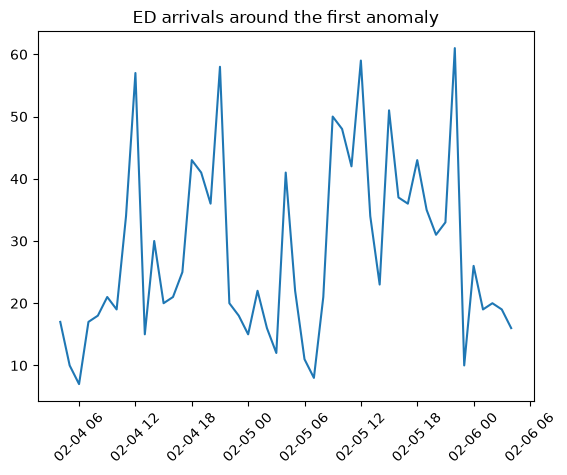

In [24]:
i = ed_df[ed_df['is_anomaly'] == 1].index[0]
window = ed_df.loc[i-24:i+24]

plt.plot(window['timestamp'], window['arrivals'])
plt.xticks(rotation=45)
plt.title('ED arrivals around the first anomaly')
plt.show()

## 3. Z-score
How far is this hour's arrivals above the usual for the same hour and day of week?

`z = (arrivals - usual average) / usual spread`

In [25]:
g = ed_df.groupby(['hour', 'day_of_week'])['arrivals']
ed_df['z'] = (ed_df['arrivals'] - g.transform('mean')) / g.transform('std')

## 4. Choose the threshold
Higher threshold = fewer false alarms (precision up) but more missed anomalies (recall down).

In [26]:
for t in [2.5, 3, 3.5, 4, 5]:
    pred = (ed_df['z'] > t).astype(int)
    print(f"threshold {t}: flagged {pred.sum():>3}  "
          f"precision {precision_score(ed_df['is_anomaly'], pred):.2f}  "
          f"recall {recall_score(ed_df['is_anomaly'], pred):.2f}  "
          f"f1 {f1_score(ed_df['is_anomaly'], pred):.2f}")

threshold 2.5: flagged 380  precision 0.18  recall 0.80  f1 0.30
threshold 3: flagged 184  precision 0.37  recall 0.77  f1 0.50
threshold 3.5: flagged  98  precision 0.59  recall 0.66  f1 0.62
threshold 4: flagged  65  precision 0.80  recall 0.59  f1 0.68
threshold 5: flagged  44  precision 0.95  recall 0.48  f1 0.64


Chosen threshold: **4** (precision 0.80, recall 0.59, F1 0.68, best F1). The labels were also used to choose it, so these scores are slightly optimistic. Some labelled hours look normal, so recall can never be perfect.

In [27]:
THRESHOLD = 4
pred = (ed_df['z'] > THRESHOLD).astype(int)
confusion_matrix(ed_df['is_anomaly'], pred)

array([[24235,    13],
       [   36,    52]])

## 5. Save the rule
The table of usual arrivals (mean and spread for each hour and day) plus the threshold.

In [28]:
usual = g.agg(['mean', 'std']).reset_index()

os.makedirs('saved_models', exist_ok=True)
joblib.dump({'usual': usual, 'threshold': THRESHOLD}, 'saved_models/anomaly_rule.joblib')
usual.head()

,hour,day_of_week,mean,std
0,0,0,16.068966,7.167301
1,0,1,14.262069,6.881962
2,0,2,13.737931,6.692679
3,0,3,12.931034,5.885074
4,0,4,13.951724,5.872879


## 6. Test the functions in `ml_tools.py`

In [29]:
import ml_tools

print(ml_tools.detect_anomaly(3, 0, 60))    # big surge at night -> True
print(ml_tools.detect_anomaly(11, 0, 45))   # normal rush hour -> False

{'is_anomaly': True, 'z_score': 5.8, 'usual_arrivals': 15.9}
{'is_anomaly': False, 'z_score': -0.37, 'usual_arrivals': 53.6}


In [30]:
import numpy as np

# Forecast function: average error over 200 hours (should be close to 8)
errors = []
for idx in range(20000, 20200):
    history = ed_df.iloc[idx-168:idx]
    pred_arrivals = ml_tools.predict_arrivals(history, ed_df.loc[idx, 'timestamp'])
    errors.append(abs(pred_arrivals - ed_df.loc[idx, 'arrivals']))
print('MAE over 200 hours:', round(np.mean(errors), 2))

MAE over 200 hours: 8.59
